# Conditional Variational Autoencoder (CVAE)

A standard VAE can generate a sample from its learned distribution, but a random latent draw does not let us request a particular class. A Conditional VAE (CVAE) adds a condition `c`â€”here, the MNIST digit labelâ€”to both the encoder and decoder. At generation time, we choose a label and sample `z` to generate a digit of that class.

For example, `c = 7` asks the decoder for a 7. Conditions can also be attributes or continuous measurements; this notebook uses one-hot digit labels.

## Architecture and objective

The encoder estimates the conditional posterior `q(z | x, c)` and predicts `mu` and `log_var`. The decoder models `p(x | z, c)`. We concatenate the one-hot condition with the flattened image for the encoder and with the latent vector for the decoder. This is a basic conditioning method; embeddings and feature modulation are other options.

We use a standard normal prior `p(z) = N(0, I)`. The negative conditional ELBO is:

`L_CVAE = reconstruction_loss(x, x_hat) + KL(q(z | x, c) || N(0, I))`

Reconstruction encourages faithful output given the condition; KL regularizes the posterior. The condition is learned through the paired examples and objective; the loss does not guarantee the decoder will always follow it. CVAE keeps the VAE reconstruction-plus-KL objective, while Beta-VAE changes the KL weight. The two ideas can be combined, but this notebook uses beta = 1.

## Training and generation

During training, the encoder sees the real image and its label, then the decoder reconstructs using the sampled latent vector and the same label. The reparameterization trick remains `z = mu + sigma * epsilon`.

At generation time, there is no input image to encode: choose a label `c`, sample `z ~ N(0, I)`, and decode `(z, c)`. For a fixed class, changing `z` should produce varied examples; keeping `z` fixed and changing `c` tests whether the label influences the result. Those are useful diagnostics, not proof of semantic control. This is a small MNIST demonstration, not a guarantee of disentanglement or perfect class accuracy.

In [1]:
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
num_classes = 10
device

device(type='cuda')

In [2]:
transform = transforms.ToTensor()
train_data = datasets.MNIST('data', train=True, download=True, transform=transform)
test_data = datasets.MNIST('data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)
len(train_data), len(test_data)

(60000, 10000)

## Define the conditional encoder and decoder

We use one-hot labels with ten entries. The encoder receives `[x; c]`; the decoder receives `[z; c]`. During training and reconstruction, each image is paired with its true label.

In [3]:
def one_hot(labels):
    return F.one_hot(labels, num_classes=num_classes).float()

class CVAE(nn.Module):
    def __init__(self, latent_dim=20, num_classes=10):
        super().__init__()
        self.latent_dim = latent_dim
        self.num_classes = num_classes
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28 + num_classes, 400), nn.ReLU())
        self.fc_mu = nn.Linear(400, latent_dim)
        self.fc_log_var = nn.Linear(400, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim + num_classes, 400), nn.ReLU(),
            nn.Linear(400, 28 * 28), nn.Sigmoid())

    def encode(self, x, condition):
        x = x.flatten(start_dim=1)
        h = self.encoder(torch.cat([x, condition], dim=1))
        return self.fc_mu(h), self.fc_log_var(h)

    def reparameterize(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        return mu + std * torch.randn_like(std)

    def decode(self, z, condition):
        h = torch.cat([z, condition], dim=1)
        return self.decoder(h).view(-1, 1, 28, 28)

    def forward(self, x, condition):
        mu, log_var = self.encode(x, condition)
        z = self.reparameterize(mu, log_var)
        return self.decode(z, condition), mu, log_var

def cvae_loss(reconstruction, x, mu, log_var):
    recon = F.binary_cross_entropy(reconstruction, x, reduction='none').flatten(1).sum(1).mean()
    kl = -0.5 * (1 + log_var - mu.square() - log_var.exp()).sum(1).mean()
    return recon + kl, recon, kl

model = CVAE(latent_dim=20, num_classes=num_classes).to(device)
sum(p.numel() for p in model.parameters() if p.requires_grad)

660824

## Train the CVAE

We track reconstruction and KL separately so we can see how each part contributes to the objective. The reductions are summed over each image's pixels and latent dimensions, then averaged across the batch.

In [4]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def run_epoch(loader, training):
    model.train(training)
    totals = torch.zeros(3)
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels in loader:
            images = images.to(device)
            condition = one_hot(labels.to(device))
            if training:
                optimizer.zero_grad()
            reconstruction, mu, log_var = model(images, condition)
            loss, recon, kl = cvae_loss(reconstruction, images, mu, log_var)
            if training:
                loss.backward()
                optimizer.step()
            totals += torch.tensor([loss.item(), recon.item(), kl.item()]) * images.size(0)
    return (totals / len(loader.dataset)).tolist()

epochs = 50  # Increase for sharper and more reliable generations
history = {'train': [], 'test': []}
for epoch in range(1, epochs + 1):
    train_metrics = run_epoch(train_loader, training=True)
    test_metrics = run_epoch(test_loader, training=False)
    history['train'].append(train_metrics)
    history['test'].append(test_metrics)
    print(f'Epoch {epoch:02d} | test total {test_metrics[0]:.1f} | reconstruction {test_metrics[1]:.1f} | KL {test_metrics[2]:.1f}')

Epoch 01 | test total 125.9 | reconstruction 106.7 | KL 19.2
Epoch 02 | test total 113.7 | reconstruction 92.4 | KL 21.3
Epoch 03 | test total 109.4 | reconstruction 86.8 | KL 22.6
Epoch 04 | test total 107.0 | reconstruction 85.2 | KL 21.9
Epoch 05 | test total 105.2 | reconstruction 83.1 | KL 22.2
Epoch 06 | test total 104.1 | reconstruction 81.6 | KL 22.5
Epoch 07 | test total 103.5 | reconstruction 81.4 | KL 22.1
Epoch 08 | test total 102.7 | reconstruction 80.4 | KL 22.2
Epoch 09 | test total 102.2 | reconstruction 80.3 | KL 21.9
Epoch 10 | test total 101.6 | reconstruction 79.8 | KL 21.7
Epoch 11 | test total 101.2 | reconstruction 79.6 | KL 21.6
Epoch 12 | test total 100.9 | reconstruction 79.2 | KL 21.7
Epoch 13 | test total 100.7 | reconstruction 78.9 | KL 21.8
Epoch 14 | test total 100.6 | reconstruction 78.5 | KL 22.2
Epoch 15 | test total 100.2 | reconstruction 78.6 | KL 21.7
Epoch 16 | test total 100.0 | reconstruction 78.3 | KL 21.6
Epoch 17 | test total 99.8 | reconstruc

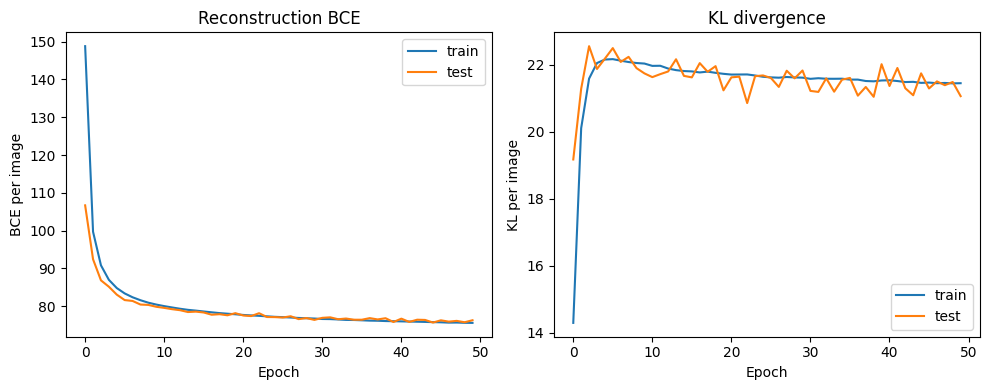

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot([m[1] for m in history['train']], label='train')
axes[0].plot([m[1] for m in history['test']], label='test')
axes[0].set(title='Reconstruction BCE', xlabel='Epoch', ylabel='BCE per image')
axes[1].plot([m[2] for m in history['train']], label='train')
axes[1].plot([m[2] for m in history['test']], label='test')
axes[1].set(title='KL divergence', xlabel='Epoch', ylabel='KL per image')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

## Reconstruct test digits

The encoder uses each test image and its true label. The decoder then reconstructs with the sampled latent code and that same condition.

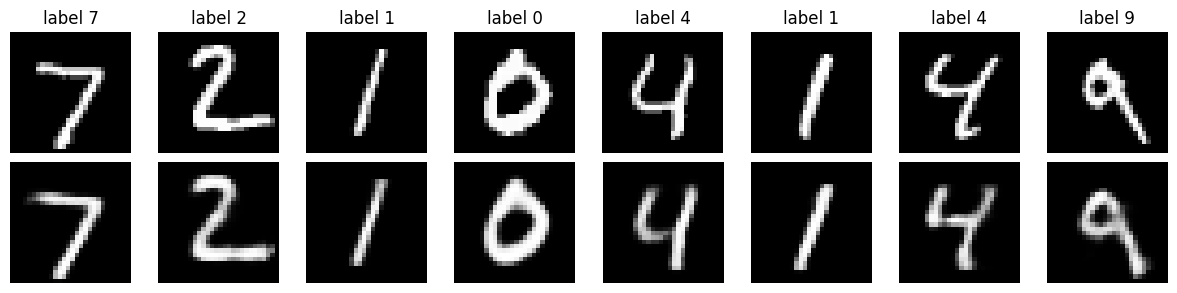

In [6]:
images, labels = next(iter(test_loader))
images, labels = images[:8].to(device), labels[:8].to(device)
conditions = one_hot(labels)
model.eval()
with torch.no_grad(): reconstructions, _, _ = model(images, conditions)
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0, i].imshow(images[i, 0].cpu(), cmap='gray')
    axes[1, i].imshow(reconstructions[i, 0].cpu(), cmap='gray')
    axes[0, i].set_title(f'label {labels[i].item()}')
    axes[0, i].axis('off'); axes[1, i].axis('off')
axes[0, 0].set_ylabel('Original'); axes[1, 0].set_ylabel('Reconstruction')
plt.tight_layout(); plt.show()

## Generate digits for a chosen condition

No encoder is needed here. Choose a label, draw latent vectors from the standard normal prior, and pass both to the decoder. Changing `z` while keeping the label fixed explores within-class variation.

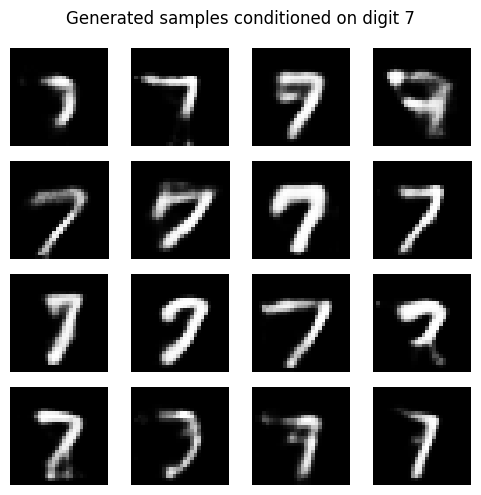

In [7]:
requested_digit = 7  # Change this to any label from 0 through 9
count = 16
condition = one_hot(torch.full((count,), requested_digit, device=device, dtype=torch.long))
z = torch.randn(count, model.latent_dim, device=device)
model.eval()
with torch.no_grad(): samples = model.decode(z, condition).cpu()
fig, axes = plt.subplots(4, 4, figsize=(5, 5))
for ax, image in zip(axes.flat, samples):
    ax.imshow(image[0], cmap='gray'); ax.axis('off')
plt.suptitle(f'Generated samples conditioned on digit {requested_digit}')
plt.tight_layout(); plt.show()

## Hold `z` fixed and change the condition

This diagnostic tests whether the label affects generation. The outputs need not share perfectly corresponding writing styles. A classifier or domain-specific evaluation can measure class agreement more systematically; here, inspect the grid and remember that visual inspection has limits.

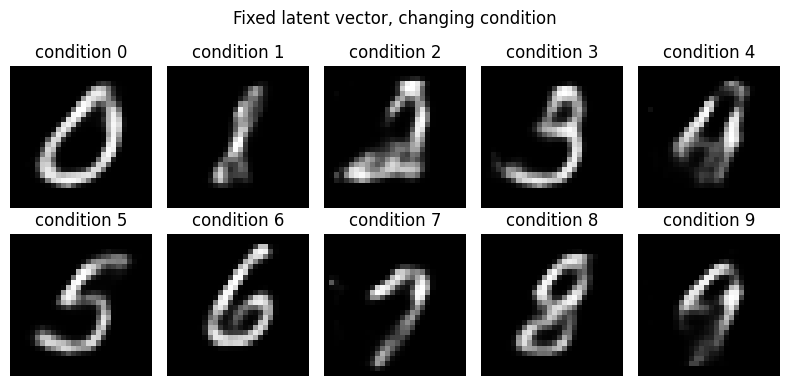

In [8]:
fixed_z = torch.randn(1, model.latent_dim, device=device).repeat(num_classes, 1)
all_conditions = one_hot(torch.arange(num_classes, device=device))
with torch.no_grad(): conditioned_grid = model.decode(fixed_z, all_conditions).cpu()
fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for digit, ax in enumerate(axes.flat):
    ax.imshow(conditioned_grid[digit, 0], cmap='gray')
    ax.set_title(f'condition {digit}'); ax.axis('off')
plt.suptitle('Fixed latent vector, changing condition')
plt.tight_layout(); plt.show()

## What to remember

- The CVAE encoder uses `(x, c)` and its decoder uses `(z, c)`.
- The objective is conditional reconstruction loss plus KL divergence.
- At generation time, sample `z` from the prior and supply the requested condition to the decoder.
- The condition specifies a class or attribute; `z` can represent variation within that condition.
- Conditioning does not guarantee correct outputs. Check condition alignment, reconstruction, diversity, and per-condition quality. Posterior collapse can still occur if the decoder ignores `z`.
- CVAE conditioning and Beta-VAE's KL weighting address different design choices and can be combined.

### Further evaluation

For a more rigorous class-conditioned check, train or use a separate classifier to measure generated-label agreement, and report it per class. A useful debugging pass checks that image-label pairs align, label encoding matches between training and generation, and changing `z` or `c` produces the expected effects. CVAEs can also suffer from limited diversity, class imbalance, poor reconstructions, invalid conditions, and condition neglect.

Applications include class- or attribute-controlled image generation and structured scientific data generation, where domain-specific validity checks are needed. A conditional GAN is another option: it uses adversarial training rather than a variational encoder and conditional ELBO; neither approach is best for every task.